# Python程序设计与数据处理 · Class 2 作业

**主题：** 收益率计算（日度 / 周度 / 月度 / 季度 / 年度、滚动与累积）
**数据：** `datasets/000001.csv` — 上证综指（000001）日度行情，1990-12-19 – 2026-10-08，共 8,737 个交易日

> 每道题都附有题目、代码与运行结果；说明性结论写在对应代码下方。

## 准备工作｜导入数据

按课堂流程读取上证综指日度数据：日期转为 datetime 并设为索引，取 1995 年以来的样本，
计算原始收益率和对数收益率。

In [1]:
import numpy as np
import pandas as pd

# 读取上证综指日度数据：日期列转 datetime 并设为索引
data = pd.read_csv('datasets/000001.csv')
data['Day'] = pd.to_datetime(data['Day'], format='%Y/%m/%d')
data.set_index('Day', inplace=True)
data = data.sort_index()

# 按课堂做法切到 1995-01 之后（1990 年首行的 Preclose 是空白字符，无法直接转数值）
data_new = data.loc['1995-01':].copy()
data_new['Close'] = pd.to_numeric(data_new['Close'])
data_new['Preclose'] = pd.to_numeric(data_new['Preclose'])

# 两种日收益率
data_new['Raw_return'] = data_new['Close'] / data_new['Preclose'] - 1
data_new['Log_return'] = np.log(data_new['Close']) - np.log(data_new['Preclose'])

data_new.head()

,Preclose,Open,Highest,Lowest,Close,Raw_return,Log_return
Day,,,,,,,
1995-01-03,647.87,637.72,647.71,630.53,639.88,-0.012333,-0.012409
1995-01-04,639.88,641.90,655.51,638.86,653.81,0.021770,0.021536
1995-01-05,653.81,655.38,657.52,645.81,646.89,-0.010584,-0.010641
1995-01-06,646.89,642.75,643.89,636.33,640.76,-0.009476,-0.009521
1995-01-09,640.76,637.52,637.55,625.04,626.00,-0.023035,-0.023305


## 题目 1｜对数收益率可加性

取 2010 全年数据，分别用两种方法计算 2010 年的对数收益率，并验证它们相等：
- 方法 A：`data_new['Log_return'].loc['2010'].sum()`
- 方法 B：`np.log(年末收盘价 / 年初前一日收盘价)`

In [2]:
# 方法A：把2010年每个交易日的对数收益率相加
A = data_new.loc['2010', 'Log_return'].sum()

# 方法B：用首尾价格直接算（年初前一日收盘价 = 2010年第一个交易日的 Preclose）
first_day = data_new.loc['2010'].index[0]
prev_close = data_new.loc[first_day, 'Preclose']
last_close = data_new.loc['2010', 'Close'].iloc[-1]
B = np.log(last_close / prev_close)

print(f'方法A（日对数收益率求和）: {A:.12f}')
print(f'方法B（首尾价格直接计算）: {B:.12f}')
print(f'|A - B| = {abs(A - B):.2e}')

方法A（日对数收益率求和）: -0.154470115020
方法B（首尾价格直接计算）: -0.154470115020
|A - B| = 3.61e-16


**结论：** 2010 年对数收益率约为 **-15.447%**（上证综指从 3277.14 点跌到 2808.08 点）。
两种方法结果一致（差异仅 3.6×10⁻¹⁶，浮点舍入误差），验证了对数收益率的可加性：
$r_{0,T}=\sum r_t$。

## 题目 2｜首日收益率为什么是 NaN

计算 `data_new['Close'].pct_change()`，观察第一个值为什么是 NaN，并思考用 `fillna(0)` 填充会带来什么问题。

In [3]:
# pct_change() 用“上一行收盘价”作分母
pct = data_new['Close'].pct_change()
pct.head(3)

Day
1995-01-03         NaN
1995-01-04    0.021770
1995-01-05   -0.010584
Name: Close, dtype: float64

In [4]:
print('NaN 个数:', pct.isna().sum())
print('NaN 出现的日期:', pct[pct.isna()].index[0].date())

# 用数据自带的 Preclose 可以算出首日真实收益率
first_real = data_new['Close'].iloc[0] / data_new['Preclose'].iloc[0] - 1
print('首日真实收益率（用 Preclose）:', f'{first_real:.4%}')

# 对比：保留 NaN 与 fillna(0)
print('均值（保留 NaN）:', pct.mean(), '| 均值（fillna(0)）:', pct.fillna(0).mean())
print('标准差（保留 NaN）:', pct.std(), '| 标准差（fillna(0)）:', pct.fillna(0).std())
print('有效样本数:', pct.count(), '->', pct.fillna(0).count())

NaN 个数: 1
NaN 出现的日期: 1995-01-03
首日真实收益率（用 Preclose）: -1.2333%
均值（保留 NaN）: 0.00036112576519840107 | 均值（fillna(0)）: 0.00036107892050191663
标准差（保留 NaN）: 0.01613621509412817 | 标准差（fillna(0)）: 0.016135168865724036
有效样本数: 7708 -> 7709


**解答：**

- **首日 NaN 是正确表示"无法计算"**：`pct_change()` 被定义为 $p_t/p_{t-1}-1$，第一行（1995-01-03）没有"上一行"收盘价，所以返回 NaN。这不是数据错误——数据自带的 `Preclose` 列显示首日真实收益是 **-1.23%**（相对 1994-12-30 收盘 647.87），说明只是 `pct_change()` 在切片后缺少前一行。
- **`fillna(0)` 的问题**：等于凭空虚构一个"当日涨跌 0%"的观测——
  - 有效样本从 7708 变成 7709，统计口径被悄悄改变；
  - 均值从 0.0361% 被拉低到 0.0361%（0.0361126% → 0.0361079%），标准差从 1.61362% 被低估到 1.61352%；
  - 若首日恰好大涨 / 大跌，会把真实的波动抹平，进而扭曲波动率、夏普比率和累计净值曲线。
- **正确做法**：保留 NaN（pandas 统计函数默认自动跳过），或直接用 `Preclose` 算出首日真实收益，或在计算前用 `dropna()` 明确剔除。

## 题目 3｜np.where 打标签

用 `np.where` 给 2020 年的日收益率打标签：收益率为正标为"涨"，否则标为"跌"，并统计上涨 / 下跌天数。

In [5]:
d2020 = data_new.loc['2020']  # 2020 全年数据

# 向量化打标签：条件为真取'涨'，否则取'跌'
labels = np.where(d2020['Raw_return'] > 0, '涨', '跌')

up = int((labels == '涨').sum())
down = int((labels == '跌').sum())
print('2020年交易日数:', len(d2020))
print(f'上涨天数: {up} | 下跌天数: {down}')
print(f'上涨占比: {up / len(d2020):.2%}')

2020年交易日数: 243
上涨天数: 131 | 下跌天数: 112
上涨占比: 53.91%


**结论：** 2020 年共 243 个交易日，其中 **131 天上涨、112 天下跌**，上涨占比 **53.91%**，
不等于 50%。原因：① 收益率分布本身左右不对称，且样本期有正漂移（2020 年上证指数上涨 13.87%）；
② "涨"按 >0 划分、"跌"包含 ≤0，本数据 2020 年恰有 0 天收益率为 0；③ 一年只有 243 个观测，
随机波动下本就不会恰好等于一半。

## 题目 4｜周度收益率

用 `resample('W-FRI')` 计算 2020 年上证指数的周度收益率（原始收益率和对数收益率都要），
并回答：一年大约有多少个交易周？周度收益率的波动比日度大还是小？为什么？

In [6]:
# 周度对数收益率 = 一周内各日对数收益率之和
week_log = d2020['Log_return'].resample('W-FRI').sum()
# 换算成周度原始收益率
week_raw = np.exp(week_log) - 1

print('周度收益记录数:', len(week_raw))
print('周度对数收益率（前3周）:')
print(week_log.head(3))
print('\n周度原始收益率（前3周）:')
print(week_raw.head(3))

周度收益记录数: 53
周度对数收益率（前3周）:
Day
2020-01-03    0.010978
2020-01-10    0.002753
2020-01-17   -0.005444
Freq: W-FRI, Name: Log_return, dtype: float64

周度原始收益率（前3周）:
Day
2020-01-03    0.011039
2020-01-10    0.002756
2020-01-17   -0.005430
Freq: W-FRI, Name: Log_return, dtype: float64


In [7]:
# 对比波动：日度 vs 周度
print('日度收益率标准差:', f"{d2020['Raw_return'].std():.4%}")
print('周度收益率标准差:', f'{week_raw.std():.4%}')
print('年化波动率（日频 ×√252）:', f"{d2020['Raw_return'].std() * np.sqrt(252):.2%}")
print('年化波动率（周频 ×√52）:', f'{week_raw.std() * np.sqrt(52):.2%}')

# 另一种做法：用每周最后一个交易日的收盘价算收益率（第一周为 NaN）
week_close = d2020['Close'].resample('W-FRI').last()
week_close.pct_change().head(3)

日度收益率标准差: 1.3085%
周度收益率标准差: 2.6582%
年化波动率（日频 ×√252）: 20.77%
年化波动率（周频 ×√52）: 19.17%


Day
2020-01-03         NaN
2020-01-10    0.002756
2020-01-17   -0.005430
Freq: W-FRI, Name: Close, dtype: float64

**解答：**

- **周数**：2020 年按 `W-FRI` 分组得到 **53 个周收益**（首个标签 2020-01-03，最后一个 2021-01-01，
  因为 2020-12-31 是周四、归入到 2021-01-01 结束的那一周）。一般年份约 **52 个交易周**
  （52 × 5 ≈ 260 个交易日，2020 年实际 243 个交易日）。
- **波动大小**：周度收益率标准差 **2.66%**，约为日度 **1.31%** 的 2 倍——**周度波动更大**。
  因为一周收益是 5 个交易日的累积，按独立同分布近似应放大 √5 ≈ 2.24 倍。
- **年化后两者接近**：日频 ×√252 = 20.77%，周频 ×√52 = 19.17%，差异来自周数取整、
  波动率聚集（volatility clustering）以及周内交易日不足 5 天。
- 若改用"周末收盘价 pct_change"，第一周会是 NaN（没有上一周收盘价），与题目 2 的道理相同。

## 题目 5｜np.select 多分类

用 `np.select` 把 2020 年每一天的收益率分为 5 类：大涨（>2%）、小涨（0~2%）、平盘（=0）、
小跌（-2%~0）、大跌（<-2%），并统计每一类的天数。

In [8]:
r = d2020['Raw_return']

# 条件按从严格到宽松排列，np.select 取第一个成立的条件
conditions = [
    r > 0.02,                  # 大涨：> 2%
    (r > 0) & (r <= 0.02),     # 小涨：0 ~ 2%
    r == 0,                    # 平盘：= 0
    (r < 0) & (r >= -0.02),    # 小跌：-2% ~ 0
]
choices = ['大涨', '小涨', '平盘', '小跌']
d2020['Magnitude'] = np.select(conditions, choices, default='大跌')

d2020['Magnitude'].value_counts()

Magnitude
小涨    117
小跌    104
大涨     14
大跌      8
Name: count, dtype: int64

**结果：** 大涨 **14** 天、小涨 **117** 天、平盘 **0** 天、小跌 **104** 天、大跌 **8** 天，
合计 243 天（2020 年没有恰好收益率为 0 的交易日）。

## 题目 6｜累积收益率的两种方法

用两种方法计算 2020 年上证指数的累积收益率曲线，并用 `np.allclose` 验证：
- 方法 A：`np.exp(Log_return.cumsum()) - 1`
- 方法 B：`(1 + Raw_return).cumprod() - 1`

In [9]:
cum_A = np.exp(d2020['Log_return'].cumsum()) - 1
cum_B = (1 + d2020['Raw_return']).cumprod() - 1

print('np.allclose:', np.allclose(cum_A, cum_B))
print('最大绝对差异:', np.abs(cum_A - cum_B).max())
print('年末累积收益率 A:', f'{cum_A.iloc[-1]:.6%}')
print('年末累积收益率 B:', f'{cum_B.iloc[-1]:.6%}')

np.allclose: True
最大绝对差异: 1.7763568394002505e-15
年末累积收益率 A: 13.866668%
年末累积收益率 B: 13.866668%


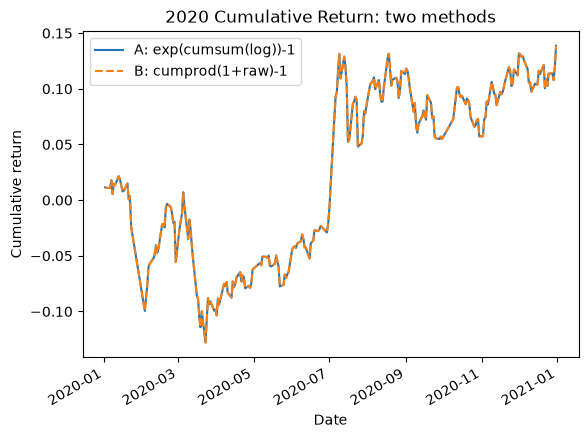

In [10]:
# 画一眼累积收益率曲线（两条线重合）
import matplotlib.pyplot as plt

cum_A.plot(label='A: exp(cumsum(log))-1')
cum_B.plot(label='B: cumprod(1+raw)-1', linestyle='--')
plt.legend()
plt.title('2020 Cumulative Return: two methods')
plt.xlabel('Date')
plt.ylabel('Cumulative return')
plt.show()

**解答：** 两种方法结果**相同**（`np.allclose` 为 True，最大差异 1.8×10⁻¹⁵，纯属浮点舍入）。
数学上它们是同一式子的两种写法：$\prod(1+R_t)=\prod e^{r_t}=e^{\sum r_t}$。

若真的出现明显差异，通常来自这几处：对数收益率与原始收益率的换算是否严格（$R=e^r-1$）、
缺失值处理（`cumsum`/`cumprod` 对 NaN 的 skipna 行为一致，但其他函数未必）、
以及收益率是用 `Preclose` 还是"上一行收盘价"算的。

## 题目 7｜滚动收益率的最大值

计算 2020 年滚动 20 日收益率（基于对数收益率累加），找出收益率最高和最低的日期。

In [11]:
# 先在完整序列上滚动（避免 2020 年初 19 个窗口不足的 NaN），再截取 2020 年
roll20 = np.exp(data_new['Log_return'].rolling(20).sum()) - 1
roll20_2020 = roll20.loc['2020']

print('2020年有效滚动值:', roll20_2020.notna().sum())
print('最高滚动20日收益率:', f'{roll20_2020.max():.2%}', '| 日期:', roll20_2020.idxmax().date())
print('最低滚动20日收益率:', f'{roll20_2020.min():.2%}', '| 日期:', roll20_2020.idxmin().date())

2020年有效滚动值: 243
最高滚动20日收益率: 17.88% | 日期: 2020-07-13
最低滚动20日收益率: -12.24% | 日期: 2020-03-23


**结果：** 最高 **+17.88%**（2020-07-13），最低 **-12.24%**（2020-03-23，新冠疫情暴跌的底部）。

注意：如果先切 2020 年再 `rolling(20)`，1 月前 19 个值会因窗口不足变成 NaN；
正确做法是在完整序列上滚动后再截取 2020 年。

## 题目 8｜索引对齐

构造下面两个 DataFrame 并相加，观察结果，回答：哪些索引是 NaN？怎样让 4 个索引都有值？

In [12]:
df1 = pd.DataFrame({'v': [1, 2, 3]}, index=['A', 'B', 'C'])
df2 = pd.DataFrame({'v': [10, 20, 30]}, index=['B', 'C', 'D'])

print('df1 + df2：')
print(df1 + df2)

print('\ndf1.add(df2, fill_value=0)：')
print(df1.add(df2, fill_value=0))

df1 + df2：
      v
A   NaN
B  12.0
C  23.0
D   NaN

df1.add(df2, fill_value=0)：
      v
A   1.0
B  12.0
C  23.0
D  30.0


**解答：** 直接相加时 pandas **按索引对齐**，只保留两者共有的索引做运算：
- **A、D 为 NaN**（分别只出现在 df1、df2 中），B=12、C=23 正常相加；
- 想让 4 个索引都有值，用 `df1.add(df2, fill_value=0)`：缺失的一侧先按 0 参与运算，
  得到 A=1、B=12、C=23、D=30。

## 题目 9｜2020 年买入持有

假设在 2020 年第一个交易日买入上证指数，一直持有到 2020 年最后一个交易日：
计算这笔投资的累积收益率；如果投入 10 万元，年底变成多少钱？

In [13]:
buy_price = d2020['Close'].iloc[0]    # 2020-01-02 收盘价
sell_price = d2020['Close'].iloc[-1]  # 2020-12-31 收盘价
total_return = sell_price / buy_price - 1

print('买入日:', d2020.index[0].date(), '收盘:', buy_price)
print('卖出日:', d2020.index[-1].date(), '收盘:', sell_price)
print('2020年累积收益率:', f'{total_return:.4%}')
print('10万元 ->', f'{100000 * (1 + total_return):,.2f} 元')

# 课程口径（对数收益率累加）：相当于 2019-12-31 收盘买入
course_ret = np.exp(d2020['Log_return'].sum()) - 1
print('\n课程口径的全年收益率（含首日相对2019年末的涨幅）:', f'{course_ret:.4%}')
print('差异来自首日涨幅:', f"{d2020['Raw_return'].iloc[0]:.4%}")

买入日: 2020-01-02 收盘: 3085.2
卖出日: 2020-12-31 收盘: 3473.07
2020年累积收益率: 12.5720%
10万元 -> 112,571.96 元

课程口径的全年收益率（含首日相对2019年末的涨幅）: 13.8667%
差异来自首日涨幅: 1.1501%


**解答：**

- 按"第一个交易日收盘买入"的严格口径：2020-01-02 收盘 **3085.20** 买入、2020-12-31 收盘 **3473.07** 卖出，
  全年累积收益率 **12.57%**；投入 10 万元，年底约为 **112,571.96 元**（盈利 12,571.96 元）。
- 若沿用课程的"全年收益率"口径（对数收益率按年累加，等价于在 **2019-12-31** 收盘买入），
  结果是从 3050.12 涨到 3473.07，收益率 **13.87%**，10 万元变为 113,866.67 元。
- 两个口径相差的正是 2020 年首个交易日（1 月 2 日）相对 2019 年末的涨幅 **1.15%**。